# GeoRAG-EuroSAT : annoter des images satellitaires et les interroger en langage naturel

**Auteur :** Mohamed Ghandour — ESSAI, Data Science & IA

## Introduction

Les satellites d'observation produisent chaque jour des milliers d'images. Pour qu'un analyste puisse y retrouver « les zones agricoles proches de l'eau » ou « les quartiers résidentiels », il faut d'abord **annoter** ces images, puis les rendre **interrogeables en langage naturel**.

Ce projet construit une chaîne complète, volontairement simple, sur le jeu de données public **EuroSAT** (images Sentinel-2, 10 classes d'occupation du sol) :

1. **Classification** : prédire la classe d'occupation du sol de chaque image avec CLIP (zéro-shot, puis sonde linéaire).
2. **Description** : enrichir chaque image d'attributs visuels (végétation, eau, texture) et générer une fiche textuelle en français.
3. **Base de connaissances** : stocker les fiches et les embeddings dans une base interrogeable.
4. **Recherche** : retrouver des images à partir d'une requête en français (BM25, CLIP, et fusion hybride).
5. **RAG** : un LLM répond aux questions en s'appuyant uniquement sur les fiches retrouvées, en citant les images.
6. **Évaluation** : qualité de la classification, de la recherche (P@10, nDCG@10, MRR) et des réponses (citations valides, abstention).

```
Images EuroSAT ──► CLIP ──► classe + confiance ──┐
        │                                        ├──► fiche texte ──► BM25 ──┐
        └──► attributs visuels (RGB) ────────────┘                           ├──► fusion RRF ──► top-k ──► LLM ──► réponse citée
                         embeddings image CLIP ──────────────────────────────┘
```

## État de l'art (bref)

- **Classification d'images de télédétection.** Sur EuroSAT, les CNN entraînés de bout en bout dépassent 98 % d'exactitude (Helber et al., 2019). Les modèles vision-langage comme **CLIP** (Radford et al., 2021) permettent une classification **zéro-shot** à partir de simples descriptions textuelles, sans entraînement, mais restent moins précis sur des images aériennes basse résolution.
- **Sonde linéaire.** Entraîner une régression logistique sur les embeddings figés de CLIP donne en général un gain important pour un coût très faible : c'est le compromis retenu ici.
- **Recherche d'images par le texte.** CLIP projette textes et images dans le même espace, ce qui permet une recherche dense texte → image. Les méthodes lexicales comme **BM25** restent fortes quand les documents sont du texte structuré.
- **RAG** (Lewis et al., 2020). Un LLM génère une réponse à partir de documents retrouvés, ce qui limite les hallucinations et permet de citer ses sources. La fusion **RRF** (Cormack et al., 2009) combine simplement plusieurs classements.

## 1. Installation et configuration

In [ ]:
# Sur Colab, torch et torchvision sont déjà installés.
!pip -q install open_clip_torch transformers rank_bm25 groq

In [20]:
import os, re, json, random, unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rank_bm25 import BM25Okapi
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

N_PAR_CLASSE = 300      # images par classe (None = les 27 000 images, à réserver au GPU)
DATA_DIR = "./data"
OUT_DIR = "./outputs"
os.makedirs(OUT_DIR, exist_ok=True)

LLM_MODEL = "openai/gpt-oss-120b"   # modèle Groq ; à changer s'il n'est plus proposé

## 2. Données : EuroSAT (RGB)

EuroSAT contient 27 000 images Sentinel-2 de 64 × 64 pixels (10 m par pixel), réparties en 10 classes. On utilise la version RGB fournie par `torchvision`. Pour que le notebook tourne en quelques minutes, on tire un échantillon équilibré de `N_PAR_CLASSE` images par classe.

In [ ]:
import torch
from torchvision.datasets import EuroSAT

ds = EuroSAT(root=DATA_DIR, download=True)
CLASSES = ds.classes
labels_all = np.array(ds.targets)

idx = []
for c in range(len(CLASSES)):
    ci = np.where(labels_all == c)[0]
    if N_PAR_CLASSE:
        ci = np.random.choice(ci, min(N_PAR_CLASSE, len(ci)), replace=False)
    idx.extend(ci.tolist())
idx = np.array(sorted(idx))

images = [ds[i][0].convert("RGB") for i in idx]
y = labels_all[idx]
image_ids = [f"EUROSAT_{i:05d}" for i in idx]
print(f"{len(images)} images, {len(CLASSES)} classes")

100%|██████████| 94.3M/94.3M [00:00<00:00, 110MB/s]


3000 images, 10 classes


In [ ]:
# Noms français et grands types de paysage
FR = {
    "AnnualCrop": "culture annuelle", "Forest": "forêt",
    "HerbaceousVegetation": "végétation herbacée", "Highway": "autoroute",
    "Industrial": "zone industrielle", "Pasture": "pâturage",
    "PermanentCrop": "culture permanente", "Residential": "zone résidentielle",
    "River": "rivière", "SeaLake": "mer ou lac",
}
GROUPE = {
    "AnnualCrop": "agricole", "PermanentCrop": "agricole", "Pasture": "agricole",
    "Forest": "naturel", "HerbaceousVegetation": "naturel",
    "River": "eau", "SeaLake": "eau",
    "Highway": "artificialisé", "Industrial": "artificialisé", "Residential": "artificialisé",
}

# Découpage stratifié : 70 % pour entraîner la sonde, 30 % forment la base de connaissances
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.30,
                                  stratify=y, random_state=SEED)
print(f"Entraînement : {len(idx_tr)} images | Base de connaissances : {len(idx_te)} images")

Entraînement : 2100 images | Base de connaissances : 900 images


### Analyse exploratoire

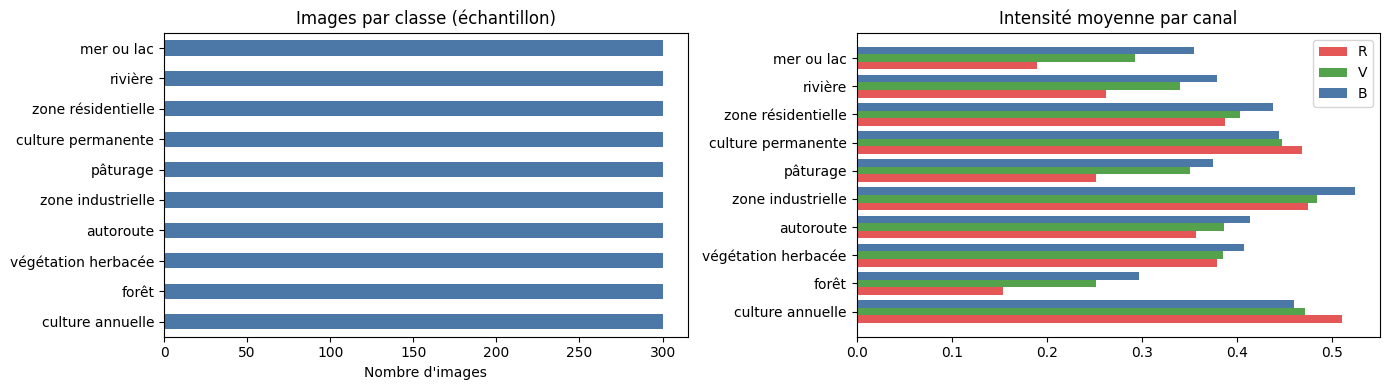

In [ ]:
counts = pd.Series([CLASSES[c] for c in y]).value_counts().reindex(CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
counts.rename(index=FR).plot.barh(ax=axes[0], color="#4C78A8")
axes[0].set_title("Images par classe (échantillon)"); axes[0].set_xlabel("Nombre d'images")

# Couleur moyenne par classe : un premier indice de séparabilité
mean_rgb = np.array([np.mean([np.asarray(images[i], dtype=np.float32).mean((0, 1))
                              for i in np.where(y == c)[0][:200]], axis=0)
                     for c in range(len(CLASSES))]) / 255
for k, (col, name) in enumerate(zip(["#E45756", "#54A24B", "#4C78A8"], "RVB")):
    axes[1].barh(np.arange(len(CLASSES)) + (k - 1) * 0.27, mean_rgb[:, k], height=0.27,
                 color=col, label=name)
axes[1].set_yticks(range(len(CLASSES))); axes[1].set_yticklabels([FR[c] for c in CLASSES])
axes[1].set_title("Intensité moyenne par canal"); axes[1].legend()
plt.tight_layout(); plt.show()

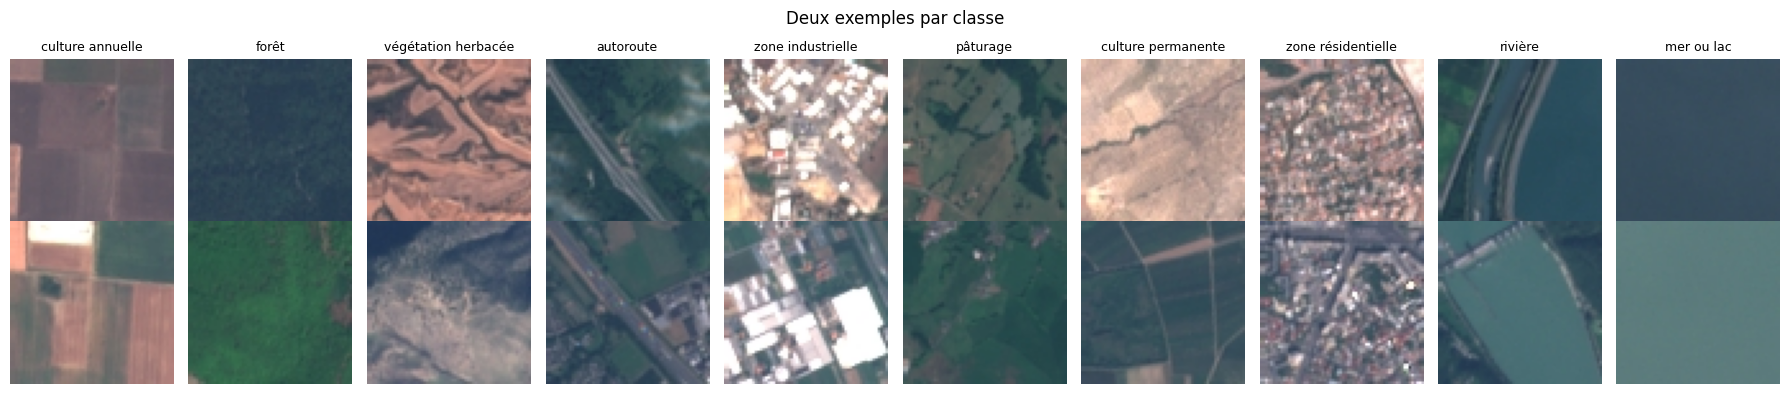

In [ ]:
fig, axes = plt.subplots(2, 10, figsize=(18, 4))
for c in range(len(CLASSES)):
    for r, i in enumerate(np.where(y == c)[0][:2]):
        axes[r, c].imshow(images[i]); axes[r, c].axis("off")
    axes[0, c].set_title(FR[CLASSES[c]], fontsize=9)
plt.suptitle("Deux exemples par classe"); plt.tight_layout(); plt.show()

## 3. Classification avec CLIP

On utilise un CLIP **multilingue** (`xlm-roberta-base-ViT-B-32`, entraîné sur LAION-5B) : son encodeur de texte comprend le français, ce qui servira aussi pour la recherche.

Les images sont encodées une seule fois ; les embeddings normalisés servent à la classification, puis à la recherche.

In [ ]:
import open_clip

device = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME, PRETRAINED = "xlm-roberta-base-ViT-B-32", "laion5b_s13b_b90k"
clip_model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME, pretrained=PRETRAINED, device=device)
tokenizer = open_clip.get_tokenizer(MODEL_NAME)
clip_model.eval()

@torch.no_grad()
def encode_images(imgs, bs=128):
    out = []
    for i in range(0, len(imgs), bs):
        x = torch.stack([preprocess(im) for im in imgs[i:i + bs]]).to(device)
        e = clip_model.encode_image(x)
        out.append((e / e.norm(dim=-1, keepdim=True)).float().cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def encode_texts(texts, bs=256):
    out = []
    for i in range(0, len(texts), bs):
        e = clip_model.encode_text(tokenizer(texts[i:i + bs]).to(device))
        out.append((e / e.norm(dim=-1, keepdim=True)).float().cpu().numpy())
    return np.concatenate(out)

print("Appareil :", device)

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.46GB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Appareil : cpu


In [8]:
E = encode_images(images)          # (n_images, d), normalisé
np.save(f"{OUT_DIR}/clip_image_embeddings.npy", E)
print("Embeddings :", E.shape)

Embeddings : (3000, 512)


### 3.1 Zéro-shot

Chaque classe est décrite par plusieurs phrases en français ; on moyenne leurs embeddings (*prompt ensembling*) et on prédit la classe la plus proche de l'image.

In [9]:
TEMPLATES = ["une image satellite de {}", "une photo aérienne de {}", "vue du ciel : {}"]

def class_text_embeddings():
    T = []
    for c in CLASSES:
        t = encode_texts([tpl.format(FR[c]) for tpl in TEMPLATES]).mean(0)
        T.append(t / np.linalg.norm(t))
    return np.stack(T)

T_cls = class_text_embeddings()
zs_pred = (E[idx_te] @ T_cls.T).argmax(1)
y_te = y[idx_te]
print(f"Zéro-shot  : exactitude {accuracy_score(y_te, zs_pred):.3f} | "
      f"F1 macro {f1_score(y_te, zs_pred, average='macro'):.3f}")

Zéro-shot  : exactitude 0.540 | F1 macro 0.464


### 3.2 Sonde linéaire

Une régression logistique entraînée sur les embeddings figés (70 % des images). Ses probabilités servent de **confiance** dans les fiches.

In [10]:
clf = LogisticRegression(max_iter=3000, C=1.0)
clf.fit(E[idx_tr], y[idx_tr])
proba_te = clf.predict_proba(E[idx_te])
lp_pred = proba_te.argmax(1)

resultats_clf = pd.DataFrame({
    "Méthode": ["CLIP zéro-shot", "CLIP + sonde linéaire"],
    "Exactitude": [accuracy_score(y_te, zs_pred), accuracy_score(y_te, lp_pred)],
    "F1 macro": [f1_score(y_te, zs_pred, average="macro"), f1_score(y_te, lp_pred, average="macro")],
}).round(3)
display(resultats_clf)
print(classification_report(y_te, lp_pred, target_names=[FR[c] for c in CLASSES], digits=3, zero_division=0))

,Méthode,Exactitude,F1 macro
0,CLIP zéro-shot,0.54,0.464
1,CLIP + sonde linéaire,0.91,0.910


                     precision    recall  f1-score   support

   culture annuelle      0.832     0.933     0.880        90
              forêt      0.887     0.956     0.920        90
végétation herbacée      0.837     0.856     0.846        90
          autoroute      0.987     0.867     0.923        90
  zone industrielle      0.946     0.967     0.956        90
           pâturage      0.941     0.889     0.914        90
 culture permanente      0.902     0.822     0.860        90
 zone résidentielle      0.945     0.956     0.950        90
            rivière      0.875     0.933     0.903        90
         mer ou lac      0.976     0.922     0.949        90

           accuracy                          0.910       900
          macro avg      0.913     0.910     0.910       900
       weighted avg      0.913     0.910     0.910       900



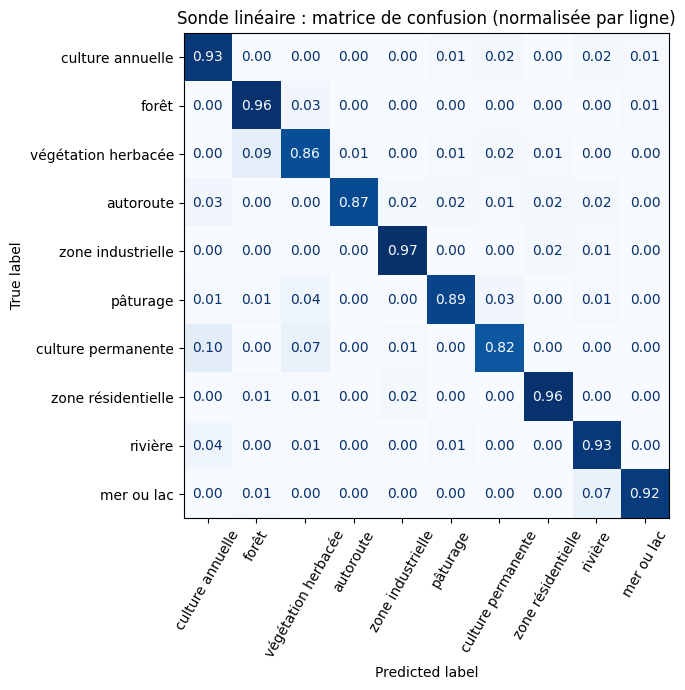

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_te, lp_pred, normalize="true"),
                       display_labels=[FR[c] for c in CLASSES]).plot(
    ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=60, colorbar=False)
ax.set_title("Sonde linéaire : matrice de confusion (normalisée par ligne)")
plt.tight_layout(); plt.show()

## 4. Description : attributs visuels et fiche textuelle

La classe seule ne suffit pas pour répondre à « des zones très végétalisées » ou « des images sombres ». On calcule donc quatre attributs simples à partir des pixels RGB :

| Attribut | Calcul |
| --- | --- |
| Végétation | part des pixels où l'indice *Excess Green* (2G − R − B) dépasse 0,05 |
| Eau | part des pixels sombres où le bleu domine |
| Luminosité | intensité moyenne |
| Texture | gradient moyen (différences entre pixels voisins) |

Chaque attribut est converti en niveau (faible / moyen / élevé) selon les **terciles** de la base, ce qui évite de fixer des seuils arbitraires. On ajoute enfin des **mots-clés** par classe (enrichissement sémantique), puis on génère une fiche en français.

In [12]:
def attributs(img):
    a = np.asarray(img, dtype=np.float32) / 255
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    gris = a.mean(-1)
    return {
        "vegetation": float(((2 * g - r - b) > 0.05).mean()),
        "eau": float(((b > r) & (b > g) & (gris < 0.35)).mean()),
        "luminosite": float(gris.mean()),
        "texture": float(np.abs(np.diff(gris, axis=0)).mean() + np.abs(np.diff(gris, axis=1)).mean()),
    }

att = pd.DataFrame([attributs(images[i]) for i in idx_te])
NIVEAUX = {
    "vegetation": ["faible", "moyenne", "élevée"],
    "eau": ["faible", "moyenne", "élevée"],
    "luminosite": ["faible", "moyenne", "élevée"],
    "texture": ["homogène", "intermédiaire", "hétérogène"],
}
for col, mots in NIVEAUX.items():
    q1, q2 = att[col].quantile([1 / 3, 2 / 3])
    att[col + "_niveau"] = np.where(att[col] <= q1, mots[0], np.where(att[col] <= q2, mots[1], mots[2]))
att.describe().round(3)

,vegetation,eau,luminosite,texture
count,900.000,900.000,900.000,900.000
mean,0.279,0.435,0.378,0.044
std,0.328,0.365,0.119,0.033
min,0.000,0.000,0.167,0.003
25%,0.008,0.087,0.285,0.018
50%,0.126,0.370,0.366,0.034
75%,0.491,0.770,0.452,0.062
max,1.000,1.000,0.806,0.176


In [13]:
MOTS_CLES = {
    "AnnualCrop": "champs cultivés, parcelles, céréales, labours",
    "PermanentCrop": "vergers, vignes, oliviers, plantations",
    "Pasture": "prairies, herbe, élevage, bétail",
    "Forest": "arbres, bois, couvert forestier",
    "HerbaceousVegetation": "broussailles, friches, herbes, milieu naturel",
    "Highway": "route, autoroute, voie de circulation, infrastructure",
    "Industrial": "usines, entrepôts, bâtiments industriels, hangars",
    "Residential": "maisons, habitations, quartier, ville, bâtiments",
    "River": "cours d'eau, fleuve, berges",
    "SeaLake": "plan d'eau, lac, mer, côte",
}

def fiche(j):
    # Fiche de l'image j de la base (position dans idx_te)
    p = proba_te[j]; top = np.argsort(p)[::-1]
    c1, c2 = CLASSES[top[0]], CLASSES[top[1]]
    conf = "élevée" if p[top[0]] >= 0.8 else "moyenne" if p[top[0]] >= 0.5 else "faible"
    a = att.iloc[j]
    txt = (f"Image {image_ids[idx_te[j]]} : {FR[c1]}, paysage {GROUPE[c1]}, "
           f"confiance {conf} ({p[top[0]]:.2f}).")
    if p[top[1]] >= 0.15:
        txt += f" Classe secondaire possible : {FR[c2]} ({p[top[1]]:.2f})."
    txt += (f" Végétation {a.vegetation_niveau}, eau {a.eau_niveau}, "
            f"luminosité {a.luminosite_niveau}, texture {a.texture_niveau}."
            f" Mots-clés : {MOTS_CLES[c1]}.")
    return {
        "id": image_ids[idx_te[j]], "classe": c1, "classe_fr": FR[c1], "groupe": GROUPE[c1],
        "confiance": round(float(p[top[0]]), 3), "classe_secondaire": FR[c2],
        **{k: round(float(a[k]), 4) for k in NIVEAUX}, **{k + "_niveau": a[k + "_niveau"] for k in NIVEAUX},
        "description": txt,
        "classe_reelle": CLASSES[y[idx_te[j]]],   # vérité terrain, utilisée seulement pour l'évaluation
    }

kb = pd.DataFrame([fiche(j) for j in range(len(idx_te))])
kb.to_json(f"{OUT_DIR}/base_de_connaissances.jsonl", orient="records", lines=True, force_ascii=False)
for t in kb.description.sample(3, random_state=SEED): print("•", t, "\n")

• Image EUROSAT_04698 : forêt, paysage naturel, confiance moyenne (0.55). Classe secondaire possible : végétation herbacée (0.28). Végétation faible, eau élevée, luminosité faible, texture homogène. Mots-clés : arbres, bois, couvert forestier. 

• Image EUROSAT_21109 : zone résidentielle, paysage artificialisé, confiance élevée (0.84). Végétation faible, eau moyenne, luminosité moyenne, texture hétérogène. Mots-clés : maisons, habitations, quartier, ville, bâtiments. 

• Image EUROSAT_04291 : végétation herbacée, paysage naturel, confiance faible (0.34). Classe secondaire possible : forêt (0.28). Végétation moyenne, eau élevée, luminosité faible, texture intermédiaire. Mots-clés : broussailles, friches, herbes, milieu naturel. 



## 5. Base de connaissances et recherche

Trois façons de retrouver des images à partir d'une requête :

- **BM25** sur les fiches textuelles (correspondance de mots) ;
- **CLIP** : similarité entre l'embedding de la requête et celui de l'image (sens, sans passer par la fiche) ;
- **Hybride** : fusion des deux classements par *Reciprocal Rank Fusion* (RRF, k = 60).

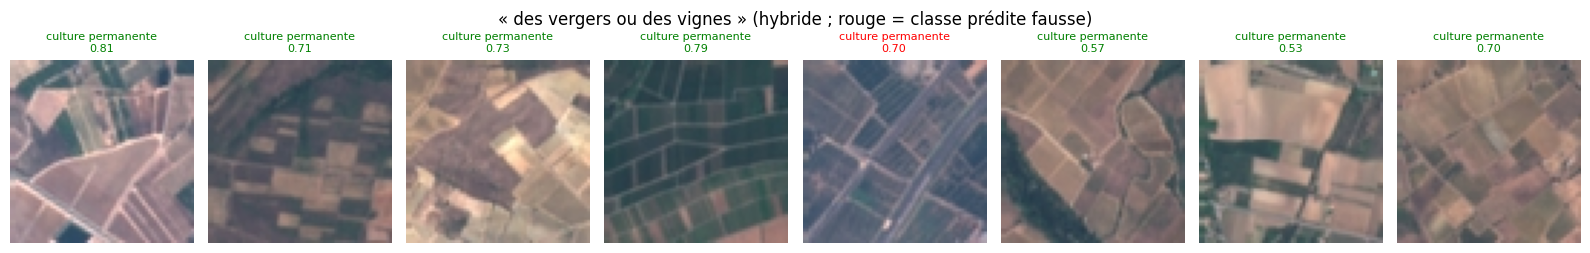

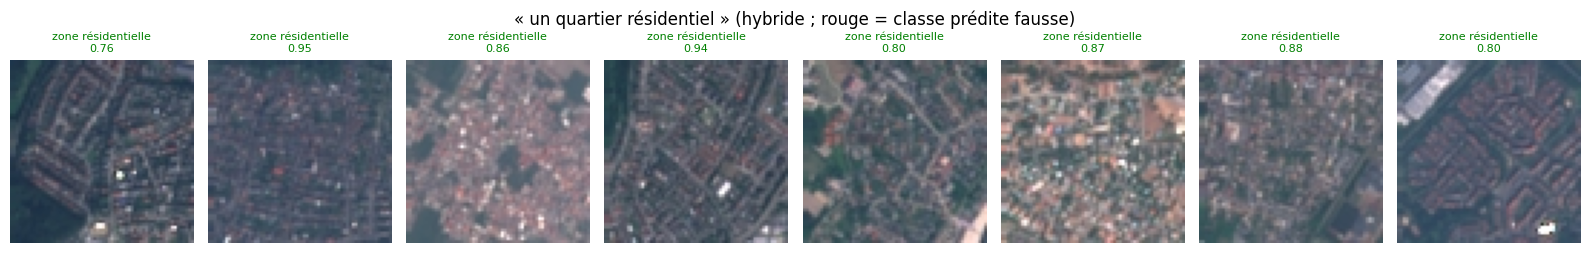

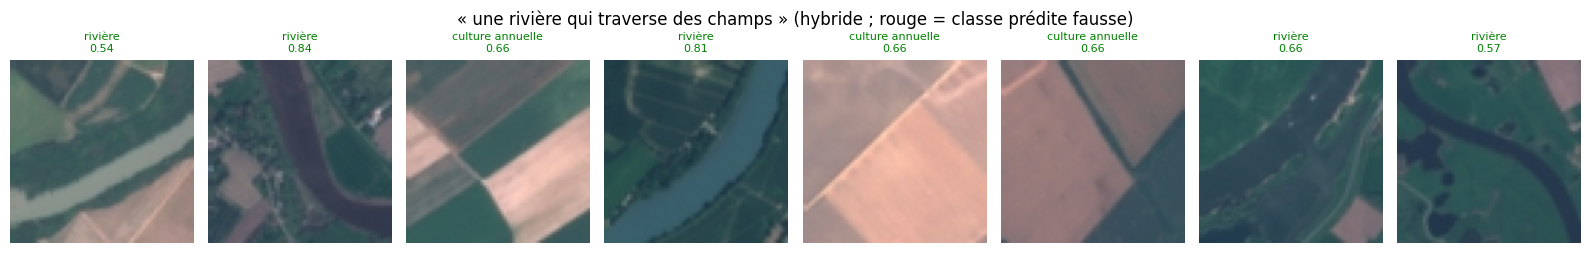

In [14]:
STOP = set("le la les de des du un une et en à a au aux avec pour par sur dans d l est sont ou qui que images image zones zone".split())

def tokens(texte):
    t = unicodedata.normalize("NFKD", texte.lower()).encode("ascii", "ignore").decode()
    return [w for w in re.findall(r"[a-z]+", t) if w not in STOP and len(w) > 1]

E_kb = E[idx_te]
bm25 = BM25Okapi([tokens(t) for t in kb.description])
bm25_sans_mots_cles = BM25Okapi([tokens(t.split(" Mots-clés")[0]) for t in kb.description])

def classement(scores):
    return np.argsort(-scores, kind="stable")

def rechercher(requete, k=10, methode="hybride", index_bm25=None):
    index_bm25 = index_bm25 or bm25
    s_bm25 = index_bm25.get_scores(tokens(requete))
    s_clip = E_kb @ encode_texts([requete])[0]
    if methode == "bm25":
        ordre, score = classement(s_bm25), s_bm25
    elif methode == "clip":
        ordre, score = classement(s_clip), s_clip
    else:  # RRF
        rang = np.empty(len(kb)); score = np.zeros(len(kb))
        for s in (s_bm25, s_clip):
            rang[classement(s)] = np.arange(1, len(kb) + 1)
            score += 1 / (60 + rang)
        ordre = classement(score)
    res = kb.iloc[ordre[:k]].copy()
    res["score"] = score[ordre[:k]]
    res["bm25_max"] = float(s_bm25.max())   # 0 = aucun mot de la requête dans la base
    return res

def afficher(res, titre=""):
    fig, axes = plt.subplots(1, len(res), figsize=(2 * len(res), 2.6))
    pos = {iid: j for j, iid in enumerate(image_ids)}
    for ax, r in zip(np.atleast_1d(axes), res.itertuples()):
        ax.imshow(images[pos[r.id]]); ax.axis("off")
        ax.set_title(f"{r.classe_fr}\n{r.confiance:.2f}", fontsize=8,
                     color="green" if r.classe == r.classe_reelle else "red")
    plt.suptitle(titre); plt.tight_layout(); plt.show()

for q in ["des vergers ou des vignes", "un quartier résidentiel", "une rivière qui traverse des champs"]:
    afficher(rechercher(q, k=8), f"« {q} » (hybride ; rouge = classe prédite fausse)")

## 6. RAG : répondre aux questions en citant les images

Le LLM reçoit les fiches des images retrouvées et doit répondre **uniquement** à partir d'elles, en citant les identifiants entre crochets. S'il ne peut pas répondre, il doit s'abstenir.

Clé API : crée une clé gratuite sur [console.groq.com](https://console.groq.com), puis, sur Colab, ajoute-la dans les secrets (icône 🔑) sous le nom `GROQ_API_KEY`. Sans clé, le notebook produit une réponse de repli sans LLM.

LLM disponible : True
Les images [EUROSAT_00266], [EUROSAT_17057] et [EUROSAT_16315] présentent des zones agricoles avec une végétation élevée. Elles sont toutes classées comme culture (annuelle ou permanente) dans un paysage agricole.


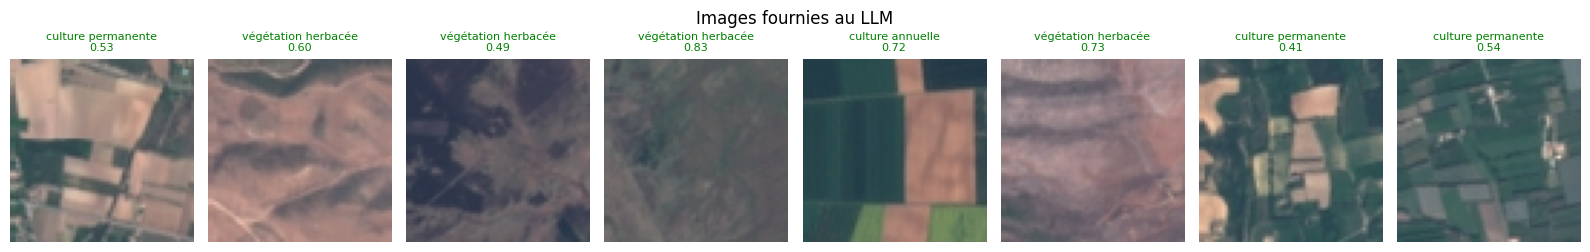

In [21]:
try:
    from google.colab import userdata
    os.environ.setdefault("GROQ_API_KEY", userdata.get("GROQ_API_KEY") or "")
except Exception:
    pass

client = None
if os.environ.get("GROQ_API_KEY"):
    from groq import Groq
    client = Groq(api_key=os.environ["GROQ_API_KEY"])
print("LLM disponible :", client is not None)

ABSTENTION = "Je ne peux pas répondre à partir de la base."
SYSTEME = (
    "Tu es un assistant d'analyse d'images satellitaires. Réponds en français, en 3 phrases maximum, "
    "uniquement à partir des fiches fournies. Cite chaque image utilisée avec son identifiant entre "
    f"crochets, par exemple [EUROSAT_00012]. Si les fiches ne permettent pas de répondre, réponds exactement : {ABSTENTION}"
)

def repondre(question, k=8, methode="hybride"):
    hits = rechercher(question, k=k, methode=methode)
    contexte = "\n".join(f"[{r.id}] {r.description}" for r in hits.itertuples())
    if client is None:   # repli sans LLM : résumé des classes retrouvées
        top = Counter(hits.classe_fr).most_common(2)
        reponse = (f"Images les plus pertinentes : {', '.join(f'{c} ({n})' for c, n in top)}. "
                   + " ".join(f"[{i}]" for i in hits.id[:3]))
    else:
        out = client.chat.completions.create(
            model=LLM_MODEL, temperature=0,
            messages=[{"role": "system", "content": SYSTEME},
                      {"role": "user", "content": f"Fiches :\n{contexte}\n\nQuestion : {question}"}])
        reponse = out.choices[0].message.content.strip()
    cites = set(re.findall(r"EUROSAT_\d{5}", reponse))
    return {"question": question, "reponse": reponse, "cites": cites,
            "citations_valides": cites <= set(hits.id), "abstention": ABSTENTION in reponse,
            "hits": hits}

r = repondre("Quelles images montrent des zones agricoles avec beaucoup de végétation ?")
print(r["reponse"]); afficher(r["hits"], "Images fournies au LLM")

## 7. Évaluation

### 7.1 Recherche

On écrit 20 requêtes en français, chacune associée à la ou les classes **réelles** attendues. Une image est pertinente si sa vraie classe fait partie des classes attendues. Certaines requêtes reprennent les mots des fiches, d'autres sont des **paraphrases** (« vergers ou vignes » pour *culture permanente*), pour tester la robustesse au vocabulaire.

Métriques à k = 10 : précision (P@10), nDCG@10 et MRR, moyennées sur les requêtes, avec un intervalle de confiance à 95 % par bootstrap sur les requêtes.

In [16]:
REQUETES = [
    ("des champs cultivés", ["AnnualCrop", "PermanentCrop"]),
    ("parcelles de cultures annuelles", ["AnnualCrop"]),
    ("des vergers ou des vignes", ["PermanentCrop"]),
    ("prairies pour le bétail", ["Pasture"]),
    ("une forêt dense", ["Forest"]),
    ("végétation naturelle et broussailles", ["HerbaceousVegetation"]),
    ("une autoroute qui traverse la campagne", ["Highway"]),
    ("des usines et des entrepôts", ["Industrial"]),
    ("un quartier de maisons", ["Residential"]),
    ("une rivière", ["River"]),
    ("un lac ou la mer", ["SeaLake"]),
    ("des zones avec beaucoup d'eau", ["River", "SeaLake"]),
    ("des paysages construits par l'homme", ["Highway", "Industrial", "Residential"]),
    ("zones urbaines", ["Residential", "Industrial"]),
    ("milieux naturels végétalisés", ["Forest", "HerbaceousVegetation"]),
    ("terres agricoles", ["AnnualCrop", "PermanentCrop", "Pasture"]),
    ("une route goudronnée", ["Highway"]),
    ("des bois et des arbres", ["Forest"]),
    ("une côte ou un grand plan d'eau", ["SeaLake"]),
    ("des hangars industriels", ["Industrial"]),
]

def metriques(res, attendues, k=10):
    rel = res.classe_reelle.isin(attendues).to_numpy()[:k].astype(float)
    dcg = (rel / np.log2(np.arange(2, k + 2))).sum()
    n_rel = int(kb.classe_reelle.isin(attendues).sum())
    idcg = (1 / np.log2(np.arange(2, min(k, n_rel) + 2))).sum()
    rr = 1 / (np.argmax(rel) + 1) if rel.any() else 0.0
    return {"P@10": rel.mean(), "nDCG@10": dcg / idcg if idcg else 0.0, "MRR": rr}

def bootstrap_ic(valeurs, n=2000):
    v = np.asarray(valeurs); rng = np.random.default_rng(SEED)
    moy = rng.choice(v, (n, len(v))).mean(1)
    return np.percentile(moy, [2.5, 97.5])

lignes, par_requete = [], {}
systemes = {
    "BM25 (fiches sans mots-clés)": dict(methode="bm25", index_bm25=bm25_sans_mots_cles),
    "BM25 (fiches + mots-clés)": dict(methode="bm25"),
    "CLIP texte → image": dict(methode="clip"),
    "Hybride (RRF)": dict(methode="hybride"),
}
for nom, kw in systemes.items():
    m = pd.DataFrame([metriques(rechercher(q, k=10, **kw), att_) for q, att_ in REQUETES])
    par_requete[nom] = m
    lo, hi = bootstrap_ic(m["nDCG@10"])
    lignes.append({"Système": nom, **m.mean().round(3).to_dict(), "IC 95 % nDCG@10": f"[{lo:.2f} ; {hi:.2f}]"})
resultats_recherche = pd.DataFrame(lignes)
display(resultats_recherche)

,Système,P@10,nDCG@10,MRR,IC 95 % nDCG@10
0,BM25 (fiches sans mots-clés),0.300,0.306,0.398,[0.15 ; 0.49]
1,BM25 (fiches + mots-clés),0.840,0.840,0.856,[0.67 ; 0.97]
2,CLIP texte → image,0.710,0.731,0.858,[0.59 ; 0.85]
3,Hybride (RRF),0.865,0.865,0.889,[0.73 ; 0.98]


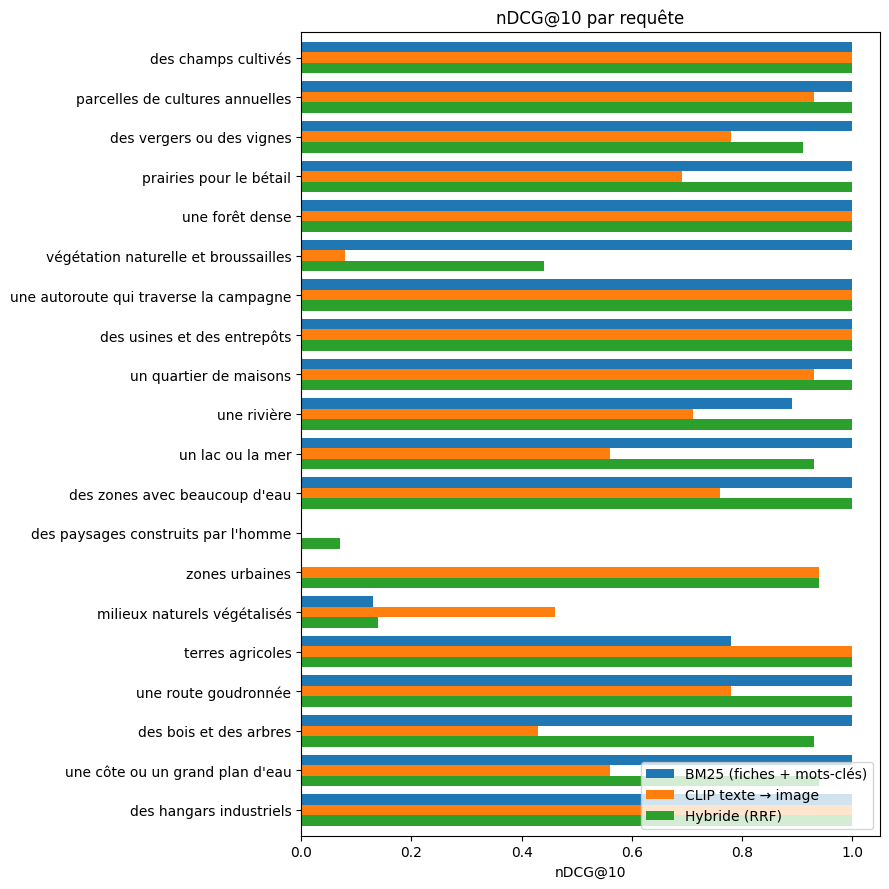

In [17]:
detail = pd.DataFrame({nom: m["nDCG@10"].values for nom, m in par_requete.items()},
                      index=[q for q, _ in REQUETES]).round(2)
ax = detail[["BM25 (fiches + mots-clés)", "CLIP texte → image", "Hybride (RRF)"]].plot.barh(
    figsize=(9, 9), width=0.8)
ax.set_xlabel("nDCG@10"); ax.set_title("nDCG@10 par requête"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

### 7.2 Réponses du LLM

Six questions : quatre auxquelles la base peut répondre, deux **hors domaine** (EuroSAT ne contient ni aéroport ni information de population) où le système doit s'abstenir. On mesure le taux de citations valides (toutes les images citées font partie des fiches fournies) et le taux d'abstention correcte.

In [22]:
QUESTIONS = [
    ("Montre-moi des images de forêt.", True),
    ("Y a-t-il des zones industrielles dans la base ?", True),
    ("Quelles images montrent de l'eau ?", True),
    ("Trouve des cultures permanentes comme des vergers.", True),
    ("Quelles images montrent un aéroport ?", False),
    ("Combien d'habitants vivent dans la zone résidentielle ?", False),
]
eval_llm = []
for q, repondable in QUESTIONS:
    r = repondre(q)
    eval_llm.append({"Question": q, "Répondable": repondable, "Abstention": r["abstention"],
                     "Nb citations": len(r["cites"]), "Citations valides": r["citations_valides"],
                     "Réponse": r["reponse"][:160]})
eval_llm = pd.DataFrame(eval_llm)
display(eval_llm)
ok = (eval_llm["Répondable"] != eval_llm["Abstention"]).mean()
print(f"Comportement correct (répond si répondable, s'abstient sinon) : {ok:.0%}")
print(f"Citations valides : {eval_llm['Citations valides'].mean():.0%}")
if client is None:
    print("⚠ Pas de clé Groq : réponses de repli, l'abstention n'est pas évaluée.")

,Question,Répondable,Abstention,Nb citations,Citations valides,Réponse
0,Montre-moi des images de forêt.,True,False,7,True,"Voici des images de forêt : [EUROSAT_03953], [..."
1,Y a-t-il des zones industrielles dans la base ?,True,False,5,True,"Oui, la base contient de nombreuses zones indu..."
2,Quelles images montrent de l'eau ?,True,False,8,True,Toutes les images suivantes montrent de l'eau ...
3,Trouve des cultures permanentes comme des verg...,True,False,8,True,Les images suivantes montrent des cultures per...
4,Quelles images montrent un aéroport ?,False,True,0,True,Je ne peux pas répondre à partir de la base.
5,Combien d'habitants vivent dans la zone réside...,False,True,0,True,Je ne peux pas répondre à partir de la base.


Comportement correct (répond si répondable, s'abstient sinon) : 100%
Citations valides : 100%


In [23]:
# Sauvegarde des résultats
resultats_clf.to_csv(f"{OUT_DIR}/resultats_classification.csv", index=False)
resultats_recherche.to_csv(f"{OUT_DIR}/resultats_recherche.csv", index=False)
eval_llm.to_csv(f"{OUT_DIR}/evaluation_llm.csv", index=False)
print(os.listdir(OUT_DIR))

['base_de_connaissances.jsonl', 'evaluation_llm.csv', 'resultats_classification.csv', 'resultats_recherche.csv', 'clip_image_embeddings.npy']


## 8. Analyse critique

Résultats obtenus sur un échantillon de 3 000 images (300 par classe), exécuté sur CPU : 2 100 images pour entraîner la sonde, 900 pour la base de connaissances.

**Classification.** La sonde linéaire atteint 0,910 d'exactitude (F1 macro 0,910), contre 0,540 en zéro-shot (F1 macro 0,464) : +37 points pour quelques secondes d'entraînement sur des embeddings figés. Le zéro-shot souffre de la basse résolution (64 × 64) et de l'écart entre les photos du web sur lesquelles CLIP a été entraîné et les vues aériennes. Les confusions restantes concernent des classes visuellement proches à 10 m par pixel : culture permanente prédite comme culture annuelle (10 %) ou végétation herbacée (7 %), végétation herbacée prédite comme forêt (9 %), mer ou lac prédit comme rivière (7 %).

**Recherche.** Les mots-clés font passer BM25 de 0,306 à 0,840 en nDCG@10 : sans eux, une paraphrase comme « vergers ou vignes » n'a aucun mot commun avec « culture permanente ». La fusion hybride obtient le meilleur score (nDCG@10 0,865, MRR 0,889), mais son intervalle de confiance [0,73 ; 0,98] chevauche celui de BM25 avec mots-clés [0,67 ; 0,97] : avec 20 requêtes, l'écart n'est pas significatif. CLIP seul atteint 0,731 sans dépendre des fiches.

Ce score de BM25 est **optimiste** : les mots-clés et les requêtes ont été écrits par la même personne et partagent du vocabulaire. Sur les requêtes sans mot commun, BM25 échoue : « zones urbaines » obtient 0 avec BM25 contre 0,94 avec CLIP. À l'inverse, CLIP échoue sur « végétation naturelle et broussailles » (0,08) là où BM25 réussit. Cette complémentarité justifie la fusion hybride. Une évaluation plus juste demanderait des requêtes écrites par une autre personne.

**RAG.** Le LLM a eu le bon comportement sur les 6 questions : il répond aux 4 questions couvertes par la base et s'abstient sur les 2 questions hors domaine (aéroport, population). Toutes les images citées faisaient partie des fiches fournies (100 % de citations valides). Avec seulement 6 questions, ce résultat reste indicatif.

**Limites.**
- Les fiches héritent des erreurs du classifieur : une image mal classée est mal décrite et mal retrouvée par BM25.
- Les attributs RGB sont des approximations : un vrai indice de végétation (NDVI) demande la bande proche infrarouge, disponible dans la version multispectrale d'EuroSAT.
- La version RGB n'a pas de coordonnées géographiques : impossible de répondre à « près de Lyon ».
- Les requêtes d'évaluation sont peu nombreuses, écrites à la main, et la pertinence est définie au niveau de la classe.
- L'échantillon de 3 000 images (exécution sur CPU) est plus petit que le jeu complet de 27 000 images.

**Pistes.** Requêtes d'évaluation rédigées indépendamment ; NDVI et NDWI sur la version multispectrale ; légendes générées par un modèle vision-langage ; images géoréférencées pour des requêtes spatiales.

## 9. Conclusion

Ce projet montre qu'une chaîne simple (embeddings CLIP, sonde linéaire, fiches textuelles et recherche hybride) suffit à rendre une collection d'images satellitaires interrogeable en français, avec des réponses vérifiables grâce aux citations. Le principal levier de qualité est l'annotation : la recherche et les réponses ne peuvent pas être meilleures que les fiches sur lesquelles elles s'appuient.

## Références

- Helber, P. et al. (2019). *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification.* IEEE JSTARS.
- Radford, A. et al. (2021). *Learning Transferable Visual Models From Natural Language Supervision.* ICML.
- Lewis, P. et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.* NeurIPS.
- Cormack, G., Clarke, C., Büttcher, S. (2009). *Reciprocal Rank Fusion outperforms Condorcet and individual rank learning methods.* SIGIR.
- Robertson, S., Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.*